# Handcrafted-feature SVM tuning

Tune the RBF SVM settings for the strongest handcrafted feature setup identified by the classical feature search. Evaluate candidate settings with the same cross-validation folds.


In [1]:
from pathlib import Path
import sys

notebook_dir = Path.cwd().resolve()
if not (notebook_dir / "utils.py").is_file():
    notebook_dir = notebook_dir / "notebooks"
sys.path.insert(0, str(notebook_dir))

from utils import setup_notebook_imports
setup_notebook_imports()

import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from src.experiments.classical_cv_experiment import load_data_splits
from src.experiments.svm_hyperparameter_search import run_svm_hyperparameter_search
from src.visualization import draw_confusion_matrix, plot_prediction_gallery

CLASS_NAMES = ["Classroom", "Library", "Cafeteria", "Parking Area", "Outdoor Campus Area"]
SPLIT_SEED = 33541943
splits = load_data_splits(seed=SPLIT_SEED, test_size=0.20)
print({name: part["images"].shape for name, part in splits.items()})

{'train': (501, 224, 224, 3), 'test': (126, 224, 224, 3)}


## Tune C and gamma

The grid has 25 settings: five `C` values and five gamma multipliers relative to each fold's `gamma=scale` value. Multiplier 1 reproduces the baseline SVM (`C=10`, gamma=`scale`). The same stratified three CV folds and five augmented copies are used for every setting; augmentation occurs only on each fold's training images. Results checkpoint to `results/svm_tuning_results.csv`.

In [2]:
def run_svm_tuning():
    """Run the fixed-feature RBF SVM hyperparameter search and display its ranking."""
    results, best = run_svm_hyperparameter_search(
        splits["train"]["images"],
        splits["train"]["labels"],
        cv_splits=3,
        copies_per_image=5,
        c_values=(0.1, 1, 10, 100, 1000),
        gamma_multipliers=(0.1, 0.3, 1, 3, 10),
        seed=SPLIT_SEED,
        output_path="results/svm_tuning_results.csv",
    )
    table = pd.DataFrame([{key: value for key, value in row.items() if key != "model"} for row in results])
    display(table)
    return results, best


results, best = run_svm_tuning()
best_model = best["model"]

Fixed features: spatial4x4_lbp_hsv_hog_full; augmented copies per image: 5.
Search: 25 C/gamma settings x 3 folds = 75 SVM fits; CV seed=33541943.
Preparing CV fold 1/3: augmentation and feature extraction.
Preparing CV fold 2/3: augmentation and feature extraction.
Preparing CV fold 3/3: augmentation and feature extraction.


RBF SVM tuning:   0%|          | 0/25 [00:00<?, ?setting/s]

1/25 C=0.1, gamma=0.1 x scale: accuracy=0.459 +/- 0.024; macro-F1=0.369 +/- 0.031
2/25 C=0.1, gamma=0.3 x scale: accuracy=0.673 +/- 0.037; macro-F1=0.664 +/- 0.039
3/25 C=0.1, gamma=1 x scale: accuracy=0.679 +/- 0.024; macro-F1=0.676 +/- 0.022
4/25 C=0.1, gamma=3 x scale: accuracy=0.244 +/- 0.003; macro-F1=0.142 +/- 0.006
5/25 C=0.1, gamma=10 x scale: accuracy=0.196 +/- 0.003; macro-F1=0.065 +/- 0.001
6/25 C=1, gamma=0.1 x scale: accuracy=0.750 +/- 0.027; macro-F1=0.750 +/- 0.026
7/25 C=1, gamma=0.3 x scale: accuracy=0.780 +/- 0.020; macro-F1=0.780 +/- 0.019
8/25 C=1, gamma=1 x scale: accuracy=0.786 +/- 0.017; macro-F1=0.786 +/- 0.017
9/25 C=1, gamma=3 x scale: accuracy=0.701 +/- 0.021; macro-F1=0.703 +/- 0.022
10/25 C=1, gamma=10 x scale: accuracy=0.224 +/- 0.024; macro-F1=0.097 +/- 0.034
11/25 C=10, gamma=0.1 x scale: accuracy=0.756 +/- 0.016; macro-F1=0.757 +/- 0.016
12/25 C=10, gamma=0.3 x scale: accuracy=0.772 +/- 0.020; macro-F1=0.772 +/- 0.019
13/25 C=10, gamma=1 x scale: accura

,feature_config,augmentation_copies,C,gamma_multiplier_of_scale,fold_gamma_values,cv_accuracy_mean,cv_accuracy_std,cv_macro_f1_mean,cv_macro_f1_std,fold_accuracies,fold_macro_f1,total_seconds
0,spatial4x4_lbp_hsv_hog_full,5,10.0,1.0,"0.33333333, 0.33333333, 0.33333333",0.796407,0.027222,0.796128,0.027178,"0.760, 0.802, 0.826","0.760, 0.802, 0.826",2461.467014
1,spatial4x4_lbp_hsv_hog_full,5,100.0,1.0,"0.33333333, 0.33333333, 0.33333333",0.796407,0.027222,0.796128,0.027178,"0.760, 0.802, 0.826","0.760, 0.802, 0.826",NaN
2,spatial4x4_lbp_hsv_hog_full,5,1000.0,1.0,"0.33333333, 0.33333333, 0.33333333",0.796407,0.027222,0.796128,0.027178,"0.760, 0.802, 0.826","0.760, 0.802, 0.826",NaN
3,spatial4x4_lbp_hsv_hog_full,5,1.0,1.0,"0.33333333, 0.33333333, 0.33333333",0.786427,0.017170,0.785806,0.017304,"0.766, 0.784, 0.808","0.766, 0.783, 0.808",NaN
4,spatial4x4_lbp_hsv_hog_full,5,1.0,0.3,"0.1, 0.1, 0.1",0.780439,0.019759,0.780362,0.019313,"0.754, 0.784, 0.802","0.755, 0.783, 0.802",NaN
5,spatial4x4_lbp_hsv_hog_full,5,10.0,0.3,"0.1, 0.1, 0.1",0.772455,0.019557,0.772327,0.019123,"0.749, 0.796, 0.772","0.749, 0.796, 0.773",NaN
6,spatial4x4_lbp_hsv_hog_full,5,100.0,0.3,"0.1, 0.1, 0.1",0.772455,0.019557,0.772327,0.019123,"0.749, 0.796, 0.772","0.749, 0.796, 0.773",NaN
7,spatial4x4_lbp_hsv_hog_full,5,1000.0,0.3,"0.1, 0.1, 0.1",0.772455,0.019557,0.772327,0.019123,"0.749, 0.796, 0.772","0.749, 0.796, 0.773",NaN
8,spatial4x4_lbp_hsv_hog_full,5,10.0,0.1,"0.033333333, 0.033333333, 0.033333333",0.756487,0.015717,0.756672,0.015634,"0.743, 0.749, 0.778","0.743, 0.748, 0.779",NaN
9,spatial4x4_lbp_hsv_hog_full,5,100.0,0.1,"0.033333333, 0.033333333, 0.033333333",0.756487,0.011291,0.755801,0.012003,"0.749, 0.749, 0.772","0.749, 0.746, 0.773",NaN


## Held-out test evaluation

Run this cell after the CV search has selected the SVM setting. It evaluates the refitted model on the held-out test split.

Test accuracy: 0.762
Test macro-F1: 0.760


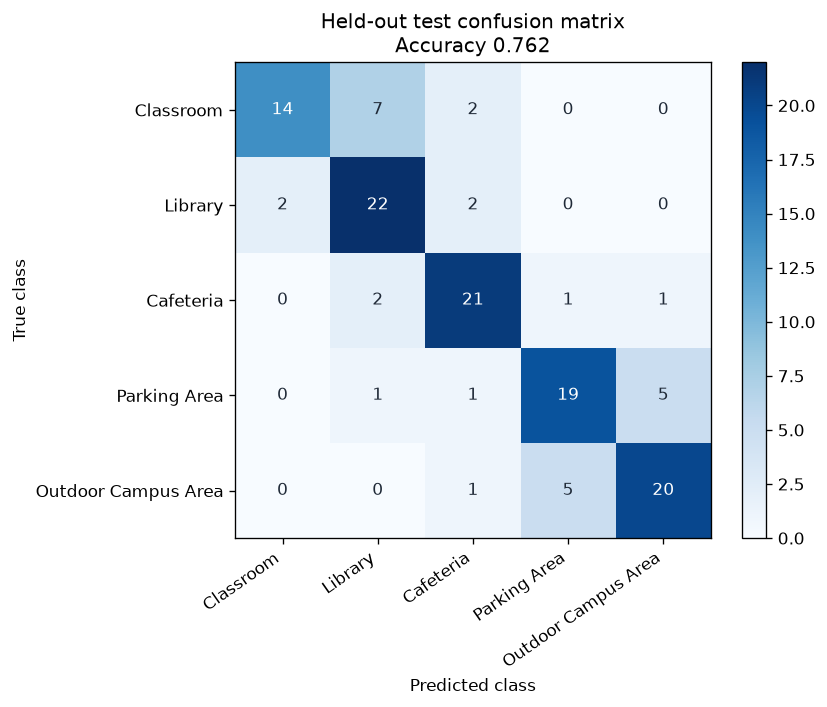

,precision,recall,f1-score,support
Classroom,0.875000,0.608696,0.717949,23.000000
Library,0.687500,0.846154,0.758621,26.000000
Cafeteria,0.777778,0.840000,0.807692,25.000000
Parking Area,0.760000,0.730769,0.745098,26.000000
Outdoor Campus Area,0.769231,0.769231,0.769231,26.000000
accuracy,0.761905,0.761905,0.761905,0.761905
macro avg,0.773902,0.758970,0.759718,126.000000
weighted avg,0.771464,0.761905,0.760332,126.000000


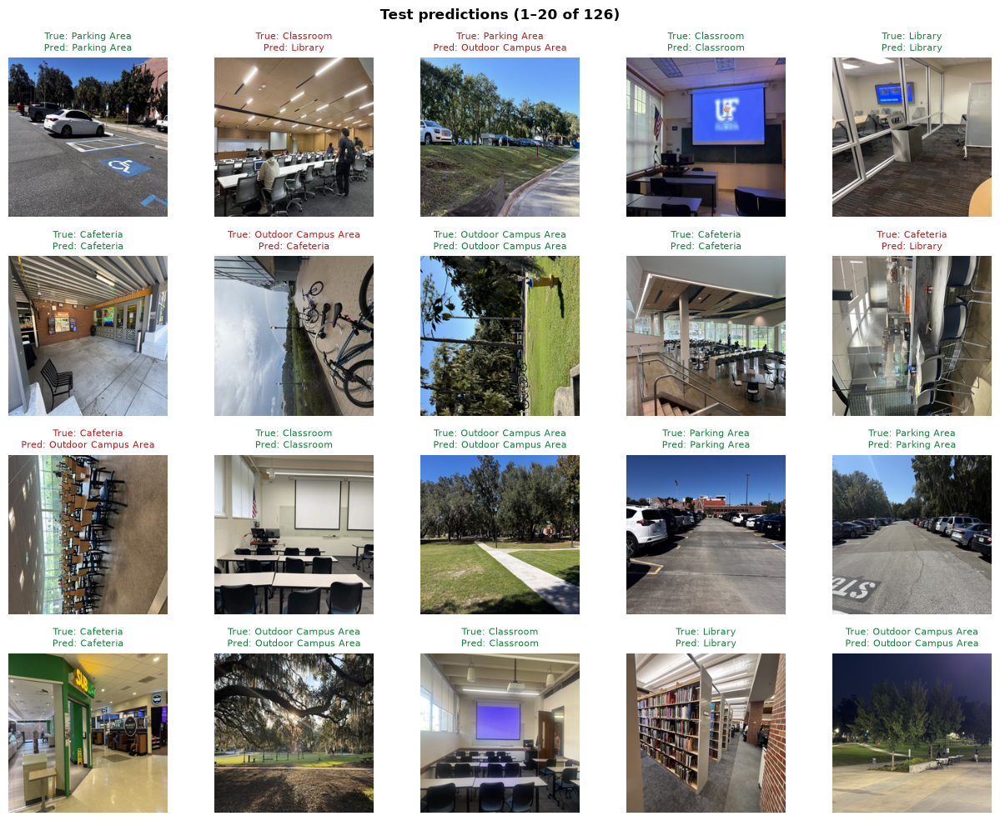

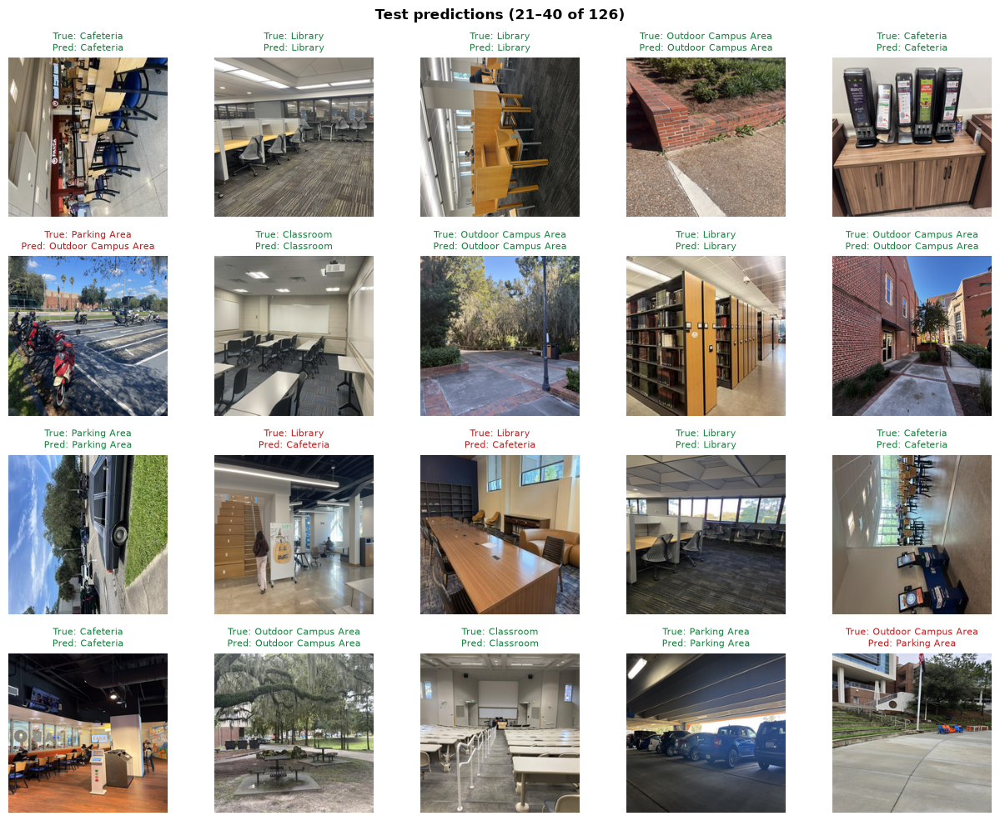

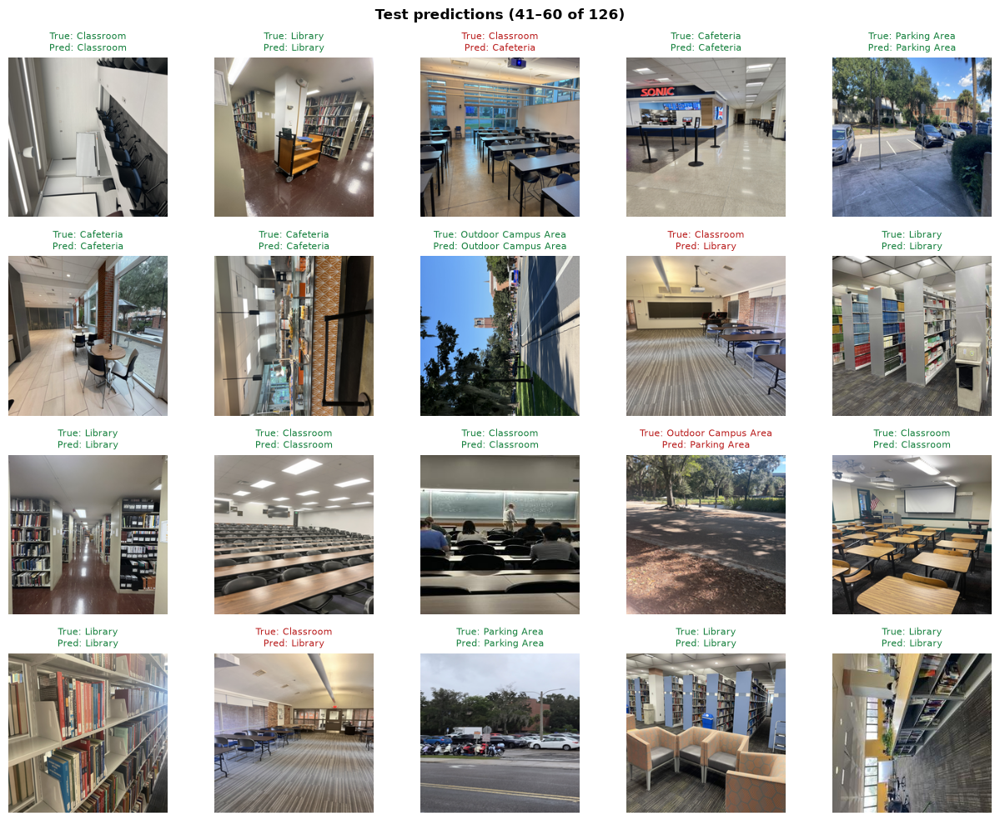

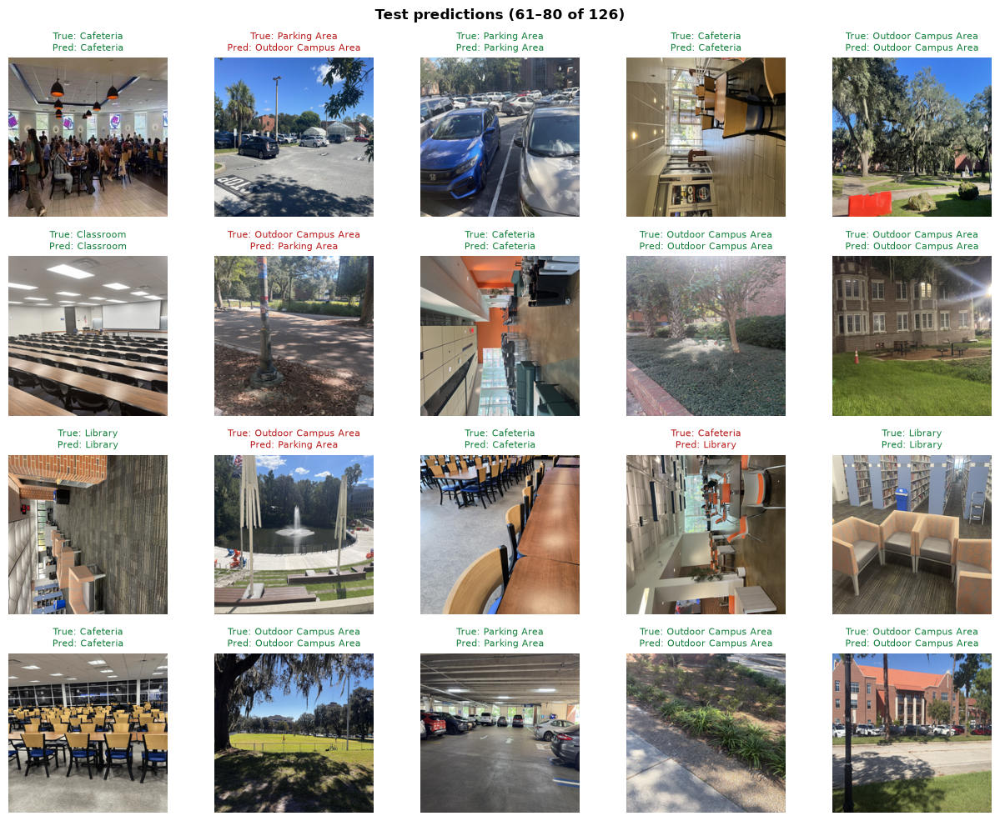

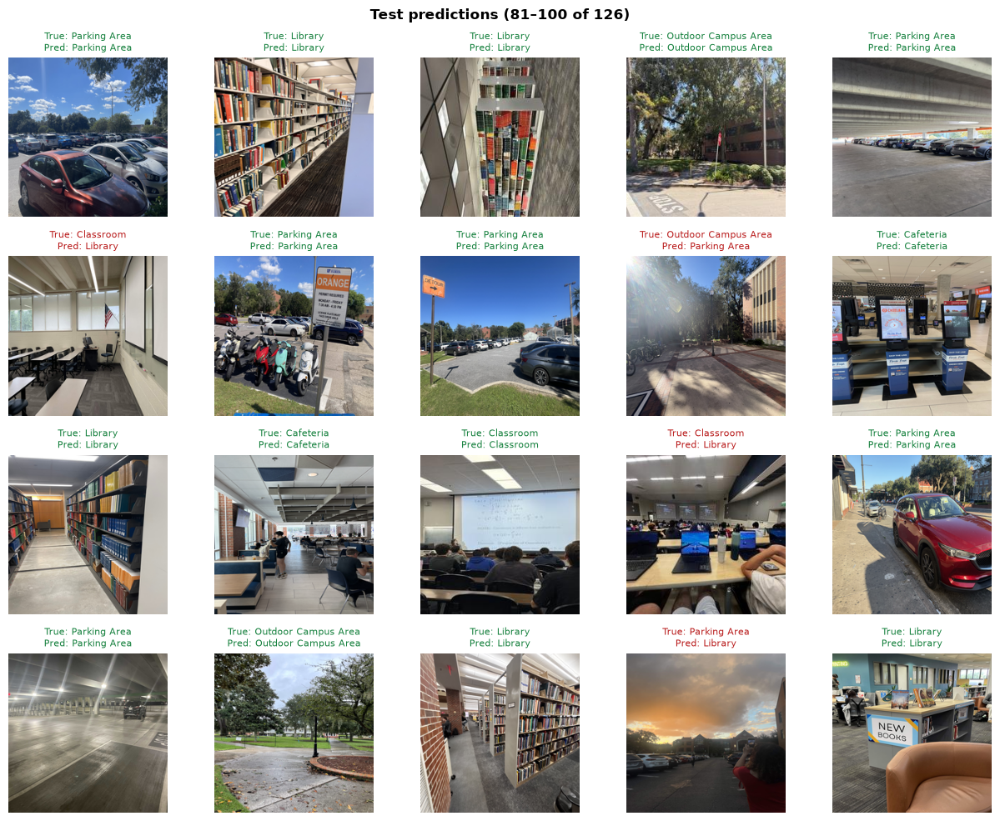

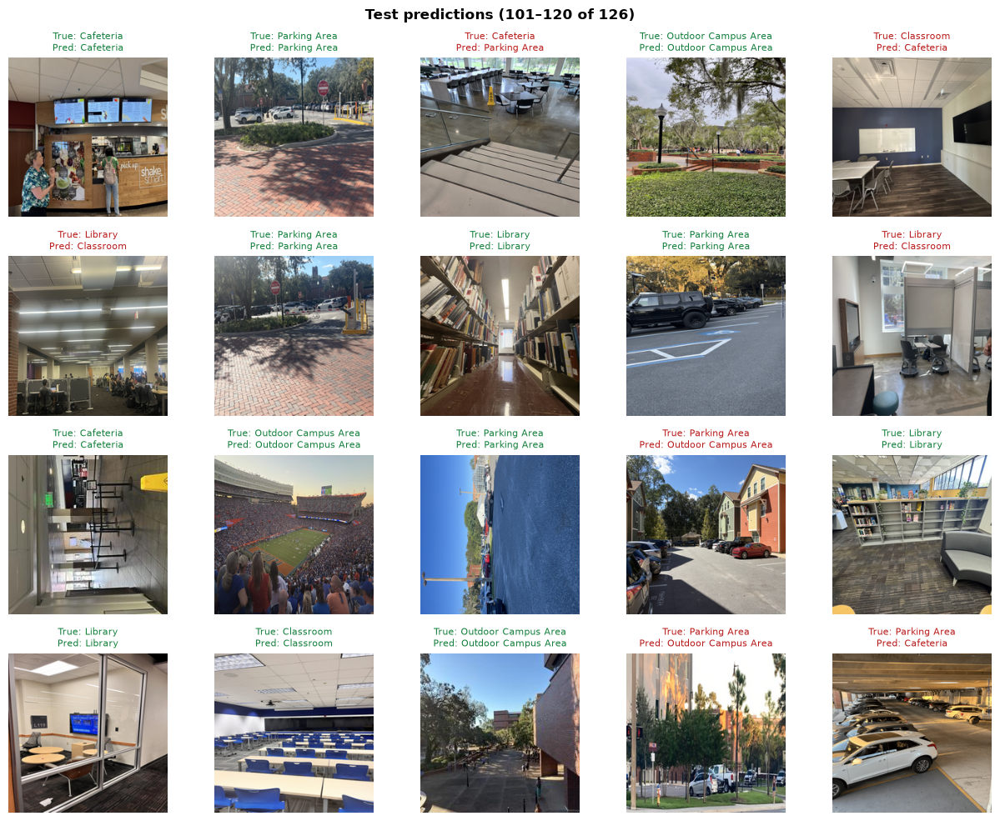

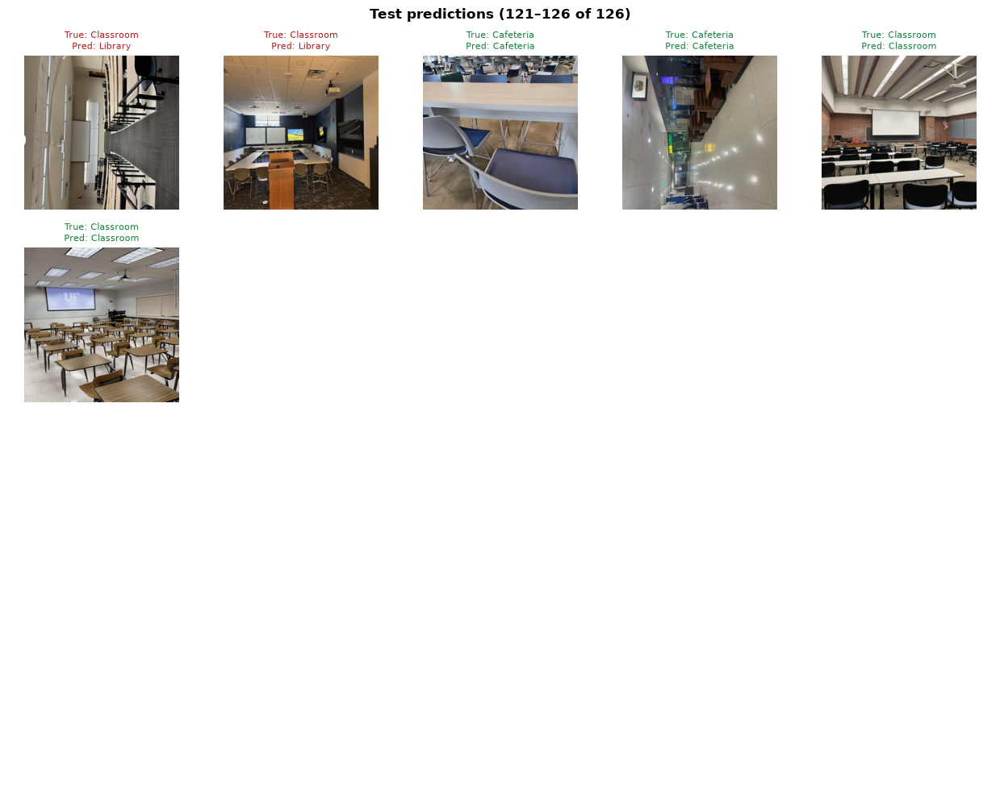

['C:\\Users\\gthra\\Coding\\Machine Learing Theory\\EEE4773_final_project\\notebooks\\results\\svm_test_prediction_gallery\\test_predictions_01.png',
 'C:\\Users\\gthra\\Coding\\Machine Learing Theory\\EEE4773_final_project\\notebooks\\results\\svm_test_prediction_gallery\\test_predictions_02.png',
 'C:\\Users\\gthra\\Coding\\Machine Learing Theory\\EEE4773_final_project\\notebooks\\results\\svm_test_prediction_gallery\\test_predictions_03.png',
 'C:\\Users\\gthra\\Coding\\Machine Learing Theory\\EEE4773_final_project\\notebooks\\results\\svm_test_prediction_gallery\\test_predictions_04.png',
 'C:\\Users\\gthra\\Coding\\Machine Learing Theory\\EEE4773_final_project\\notebooks\\results\\svm_test_prediction_gallery\\test_predictions_05.png',
 'C:\\Users\\gthra\\Coding\\Machine Learing Theory\\EEE4773_final_project\\notebooks\\results\\svm_test_prediction_gallery\\test_predictions_06.png',
 'C:\\Users\\gthra\\Coding\\Machine Learing Theory\\EEE4773_final_project\\notebooks\\results\\svm_t

In [3]:
test_labels = splits["test"]["labels"]
test_predictions = best_model.predict(splits["test"]["images"])
test_accuracy = accuracy_score(test_labels, test_predictions)
test_macro_f1 = f1_score(test_labels, test_predictions, average="macro")
print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test macro-F1: {test_macro_f1:.3f}")

fig, ax = plt.subplots(figsize=(8, 6), dpi=120)
draw_confusion_matrix(
    ax,
    confusion_matrix(test_labels, test_predictions, labels=[0, 1, 2, 3, 4]),
    CLASS_NAMES,
    f"Held-out test confusion matrix\nAccuracy {test_accuracy:.3f}",
)
fig.tight_layout()
plt.show()

display(pd.DataFrame(classification_report(
    test_labels, test_predictions, labels=[0, 1, 2, 3, 4],
    target_names=CLASS_NAMES, output_dict=True,
)).T)

plot_prediction_gallery(
    splits["test"]["images"],
    test_labels,
    test_predictions,
    probabilities=None,
    class_names=CLASS_NAMES,
    split_name="test",
    output_dir="results/svm_test_prediction_gallery",
)

## Save Model

Run this cell to save the best SVM model.

In [4]:
import joblib

model_path = Path(notebook_dir) / "results" / "svm_tuned_model.joblib"
model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(best["model"], model_path)
print(f"Saved model to: {model_path}")

Saved model to: C:\Users\gthra\Coding\Machine Learing Theory\EEE4773_final_project\notebooks\results\svm_tuned_model.joblib


## Load Model

Run this cell to load into memory the saved SVM model.

In [5]:
loaded_model = joblib.load(model_path)
test_predictions = loaded_model.predict(splits["test"]["images"])